<a href="https://colab.research.google.com/github/mrbedoya/ml-2026/blob/main/03_RegresionLineal(2da_Parte).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regresión Lineal

## 1. Librerias y configuraciones previas


In [212]:
# Tratamiento de datos
# ==============================================================================
import pandas as pd
import numpy as np


# Preprocesado y modelado
# ==============================================================================

#Separar los datos entrenamiento y prueba
from sklearn.model_selection import train_test_split

#Escalar Variables
from sklearn.preprocessing import MinMaxScaler

#Creación de modelo
from statsmodels import api as sm
from statsmodels.tools.sm_exceptions import SingularMatrixWarning
#from sklearn.linear_model import LinearRegression  # alternativa con scikit-learn (ver "Creación del modelo"); aquí se usa statsmodels

#Evaluación del modelo
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                            median_absolute_error)

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Interactuar con el sistema operativo y solicitudes HTTP
# ==============================================================================
import os
import sys
import requests
from urllib.parse import urljoin

# Configuración warnings
# ==============================================================================
import warnings
# Se ocultan solo los avisos informativos de versiones; los demás avisos siguen visibles
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)
# Aviso de matplotlib que genera internamente sm.qqplot al personalizar el color de los puntos (no afecta el resultado)
warnings.filterwarnings('ignore', message='.*redundantly defined by the')

In [213]:
# Parametros globales
# ==============================================================================

# URL base de GitHub para el repositorio
GITHUB_BASE_URL = 'https://raw.githubusercontent.com/mrbedoya/ml-2026/main/'

# Nombres de los archivos requeridos
DATASET_FILE_NAME = '01_carDetailsV4_Prep.csv'
UTILS_FILE_NAME = 'funciones.py'

# Nombres de los directorios para utilidades y datasets
DATASETS_PATH = 'datasets/'
UTILS_PATH = 'utils/'

# URL completa del dataset y utils en GitHub (urljoin evita errores con las barras)
github_dataset_url = urljoin(GITHUB_BASE_URL, DATASETS_PATH + DATASET_FILE_NAME)
github_utils_url = urljoin(GITHUB_BASE_URL, UTILS_PATH + UTILS_FILE_NAME)

# Rutas locales completas de datasets y utils
local_dataset_path = os.path.join(DATASETS_PATH, DATASET_FILE_NAME)
local_utils_path = os.path.join(UTILS_PATH, UTILS_FILE_NAME)

### (Opcional) Cargar datos desde Google Drive

La celda siguiente muestra una **alternativa** para trabajar con archivos guardados en Google Drive, en vez de descargarlos desde GitHub. Se deja comentada porque en este notebook usamos la descarga directa desde el repositorio (más fácil de reproducir para cualquier estudiante), pero queda como referencia por si prefieres montar tu propio Drive.

In [214]:
## Cargar datos desde Google Drive
## ==============================================================================

#from google.colab import drive

## Montar Google Drive
#drive.mount('/gdrive')

## Establece el directorio de trabajo dentro de directorio especificado en Google Drive
#os.chdir("/gdrive/MyDrive/01_Academia/02_Cursos/20260401_ApredinzajeAutomáticoI_UdeA/")

## Listar archivos de directorio
##!ls

In [215]:
# Funcion local para la carga de archivos
# ==============================================================================

def download_file(url, path, description, force=False, timeout=30):
    '''
    Descarga un archivo desde una URL y lo guarda localmente en un path.
    Si el archivo ya existe no se vuelve a descargar (usar force=True para obligarlo).

    Args:
        url (str): URL del archivo
        path (str): Ruta local de destino
        description (str): Descripción del archivo
        force (bool): Si es True, descarga aunque el archivo ya exista
        timeout (int): Segundos máximos de espera de la descarga
    Returns:
        None
    '''
    if os.path.exists(path) and not force:
        print(f"{description} ya existe en: {path} (no se vuelve a descargar)")
        return

    print(f"Descargando {description} desde: {url}")

    # Realiza una solicitud HTTP GET a la URL proporcionada
    response = requests.get(url, timeout=timeout)

    # Lanza una excepción si la descarga falla (código de estado HTTP no 200)
    response.raise_for_status()

    # Abre el archivo local en modo de escritura binaria ('wb')
    with open(path, 'wb') as f:
        # Escribe el contenido binario de la respuesta HTTP en el archivo local
        f.write(response.content)

    # Imprime un mensaje confirmando que la descarga fue exitosa y la ruta de guardado
    print(f"{description} descargado exitosamente a: {path}")

In [216]:
# Configuración entorno Colab
# ==============================================================================

# Creación de directorios locales
os.makedirs(DATASETS_PATH, exist_ok=True)
os.makedirs(UTILS_PATH, exist_ok=True)

# Descarga de archivos
download_file(github_dataset_url, local_dataset_path, "dataset")
download_file(github_utils_url, local_utils_path, "funciones")

dataset ya existe en: datasets/01_carDetailsV4_Prep.csv (no se vuelve a descargar)
funciones ya existe en: utils/funciones.py (no se vuelve a descargar)


## 2. Funciones

En esta sección importamos las funciones reutilizables de `funciones.py` (descargado arriba). Aquí usaremos `multiple_plot`, `tidy_corr_matrix`, `check_vif`.

In [217]:
# Funciones externas
# ==============================================================================

# Añade la ruta definida en 'UTILS_PATH' al 'sys.path' para que Python pueda encontrar módulos
sys.path.append(UTILS_PATH)

# Importa funciones externas
from funciones import multiple_plot, tidy_corr_matrix, check_vif

In [218]:
# Función para construir un modelo de regresión lineal por medio de statsmodels.api

def build_model(X,y):
    '''
    Crea y entrena un modelo de regresión lineal (OLS) con statsmodels e imprime su resumen.

    Si las variables tienen colinealidad perfecta (alguna es combinación exacta de otras) los
    coeficientes no son únicos: se informa con un mensaje y no con el SingularMatrixWarning de statsmodels.

    Args:
        X (DataFrame): variables de entrada (a las que se les adiciona la constante)
        y (array): variable de salida
    Returns:
        DataFrame: 'X' con la constante adicionada (se reutiliza en la siguiente iteración)
    '''

    #A los datos de entrada 'X' se le adiciona una constante
    X = sm.add_constant(X)

    #Se verifica si hay colinealidad perfecta: el rango de la matriz es menor que el número de columnas
    redundantes = X.shape[1] - np.linalg.matrix_rank(X.to_numpy(dtype=float))
    if redundantes > 0:
        print(f"Aviso: hay colinealidad perfecta ({redundantes} variable(s) redundante(s)); "
              "los coeficientes no son únicos. Revisa el VIF (valores muy altos o inf) y elimina variables.")

    #Se crea y se entrena el modelo de regresión lineal (statsmodels.api) con
    #los datos de entrada 'X' y los datos de salida 'y'
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', SingularMatrixWarning)   # ya se informó arriba, una sola vez
        lm = sm.OLS(y,X).fit()

    #imprime el resumen del modelo creado
    print(lm.summary()) # model summary

    return X

## 3. Carga del dataset

In [219]:
#Se crea un dataframe d con los datos obtenidos de archivo de entrada
d = pd.read_csv(local_dataset_path)

In [220]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Price               1436 non-null   float64
 1   Year                1436 non-null   int64  
 2   Kilometer           1436 non-null   int64  
 3   Engine              1436 non-null   float64
 4   Length              1436 non-null   float64
 5   Width               1436 non-null   float64
 6   Height              1436 non-null   float64
 7   Seating Capacity    1436 non-null   float64
 8   Fuel Tank Capacity  1436 non-null   float64
 9   Fuel Type           1436 non-null   object 
 10  Transmission        1436 non-null   object 
 11  Owner               1436 non-null   object 
 12  Seller Type         1436 non-null   object 
 13  Drivetrain          1436 non-null   object 
 14  PriceRange          1436 non-null   int64  
dtypes: float64(7), int64(3), object(5)
memory usage: 168.4+

## 4. Visualización de datos

### Variables de entrada

In [221]:
#Lista de variables categóricas
catCols = d.select_dtypes(include = ["object", 'category']).columns.tolist()

d[catCols].head(2)

,Fuel Type,Transmission,Owner,Seller Type,Drivetrain
0,Petrol,Manual,First,Individual,FWD
1,Petrol,Manual,First,Individual,FWD


In [222]:
#Lista de variables numéricas

numCols=d.select_dtypes(include = ['float64','float64','int32','int64']).columns.tolist()
d[numCols].head(2)

,Price,Year,Kilometer,Engine,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,PriceRange
0,9300.0000,2020,39000,1197.0000,3995.0000,1775.0000,1505.0000,5.0000,37.0000,0
1,7500.0000,2019,31000,1197.0000,3985.0000,1734.0000,1505.0000,5.0000,45.0000,0


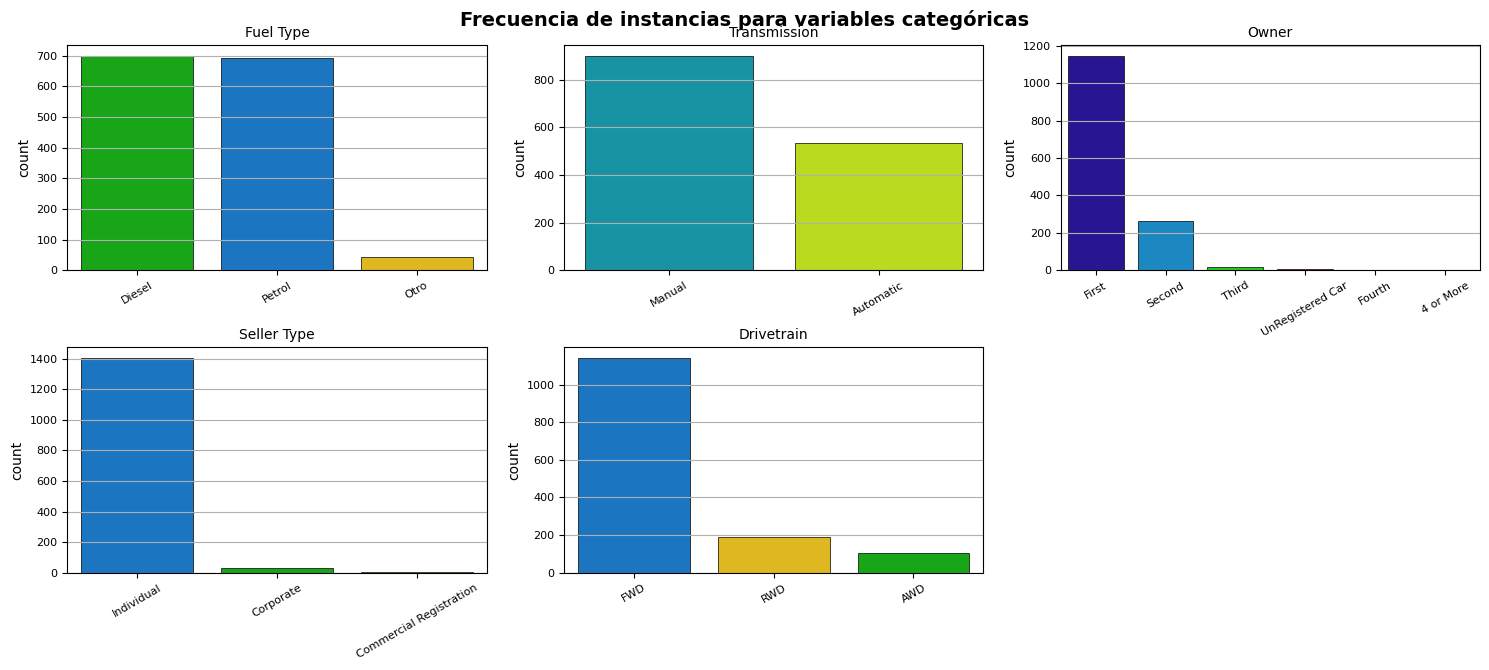

In [223]:
##Visualización de frecuencia de instancias para variables categóricas
multiple_plot(3, d , catCols, None, 'countplot', 'Frecuencia de instancias para variables categóricas',30)

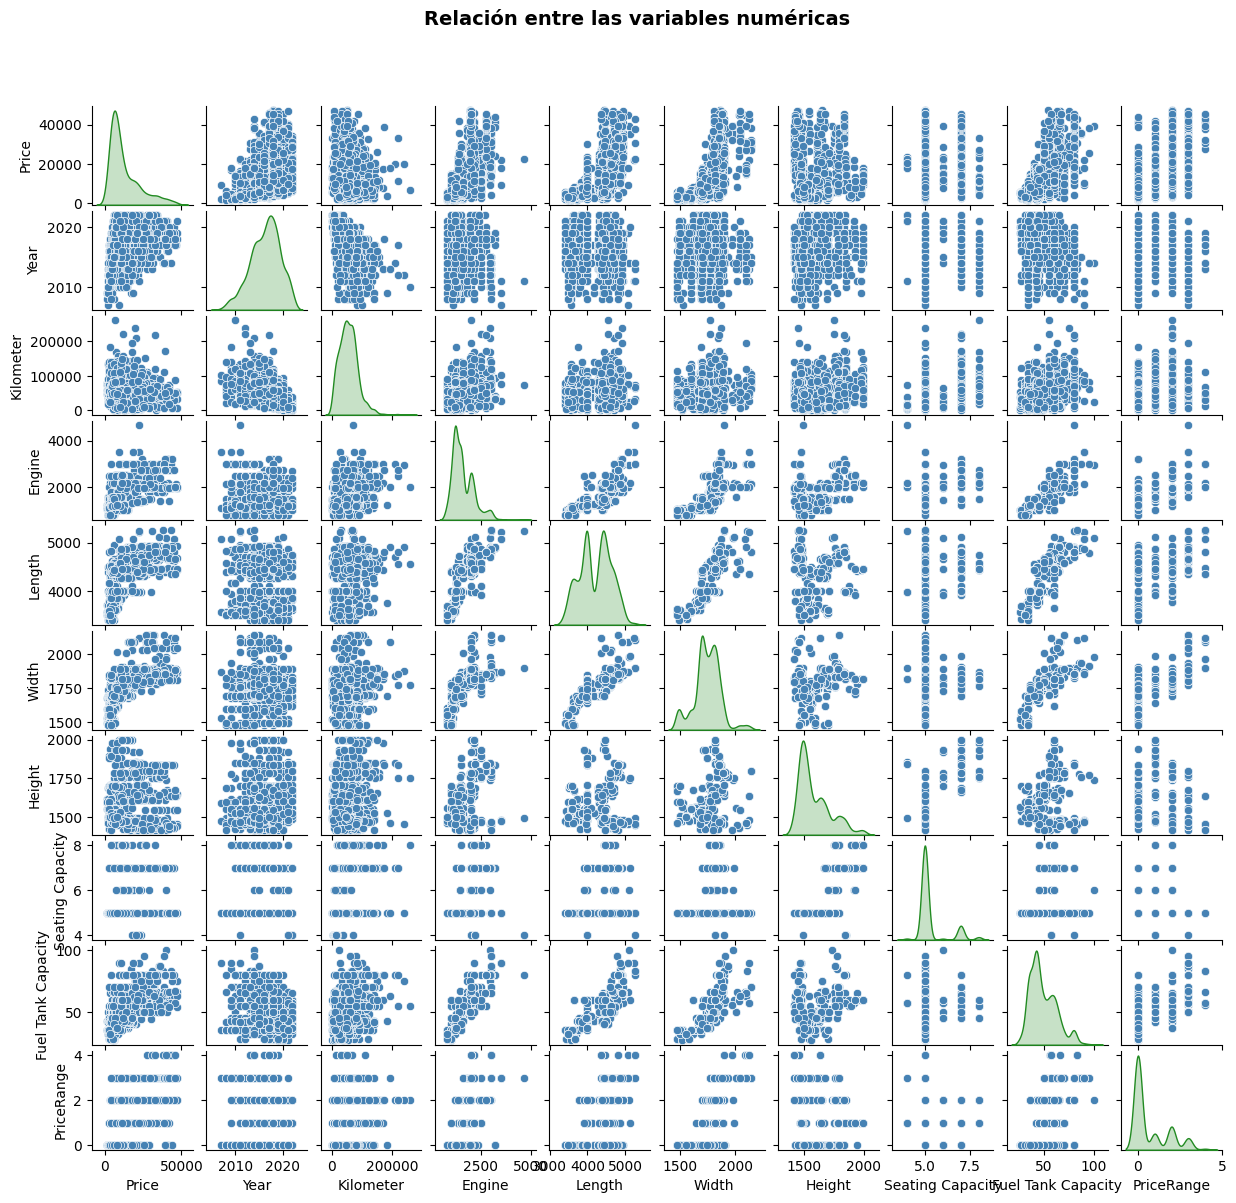

In [224]:
#Visualización de variables numéricas con respecto al precio
multiple_plot(1, d , numCols, None, 'scatterplot', 'Relación entre las variables numéricas',30)

### Variable de salida

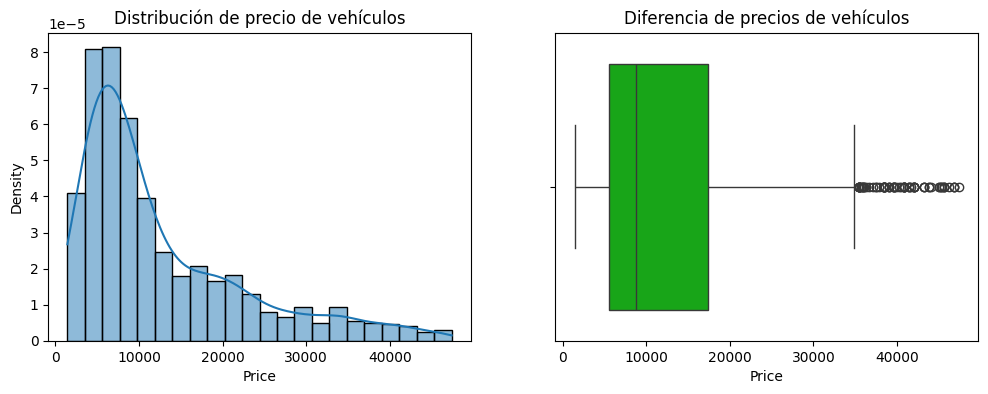

In [225]:
#Histograma y caja de bigotes del precio de los vehículos

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.title('Distribución de precio de vehículos')
sns.histplot(d.Price, kde=True, stat='density')

plt.subplot(1,2,2)
plt.title('Diferencia de precios de vehículos')
sns.boxplot(x=d.Price, palette='nipy_spectral')

plt.show()

In [226]:
pd.set_option('display.float_format', lambda x: '%.0f' % x)

print(d.Price.describe(percentiles = [0.25,0.50,0.75,0.85,0.90,0.95,0.975,1]))

count    1436
mean    12664
std      9999
min      1440
25%      5520
50%      8790
75%     17400
85%     23025
90%     28590
95%     35400
97.5%   39938
100%    47400
max     47400
Name: Price, dtype: float64


In [227]:
# Eliminar el valor 'Price' de la lista
numCols.remove('Price')

## 5. Preparación de datos

### Transformaciones para la variable de salida

In [228]:
#Transformación y = y^(1/3) Raíz cúbica

d['Price'] = np.cbrt(d['Price'])

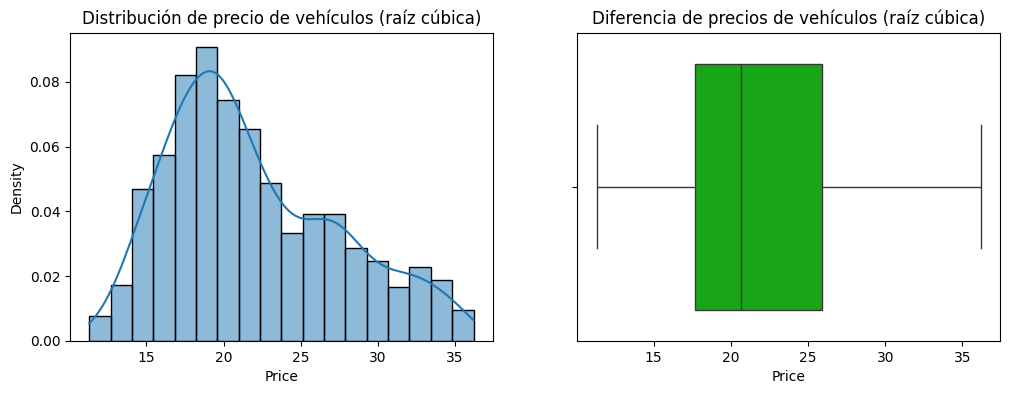

In [229]:
#Histograma y caja de bigotes del precio de los vehículos transformado

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.title('Distribución de precio de vehículos (raíz cúbica)')
sns.histplot(d.Price, kde=True, stat='density')

plt.subplot(1,2,2)
plt.title('Diferencia de precios de vehículos (raíz cúbica)')
sns.boxplot(x=d.Price, palette='nipy_spectral')

plt.show()

### Transformaciones a las variables de entrada

In [230]:
varTrans = ['Price', 'Year','Engine','Length','Width','Fuel Tank Capacity']

#multiple_plot(1, d , varTrans, None, 'scatterplot', 'Relación entre las variables numéricas',30)

In [231]:
# Transformaciones X = X^2 a las variables de entrada

varTrans = ['Year','Length','Width','Fuel Tank Capacity']

for elemento in varTrans:
    d[elemento]   = d[elemento] ** 2

### Correlaciones

In [232]:
#Generación de la matriz de correlación (incluye la variable de salida 'Price')
matrizCorr = d[['Price']+numCols].corr()

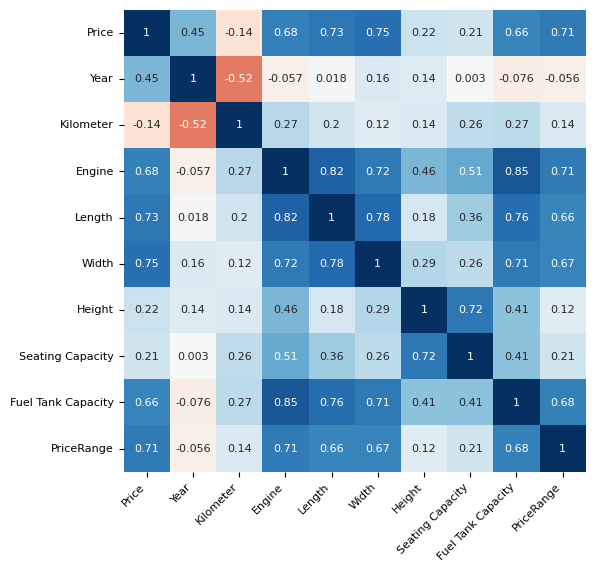

In [233]:
# Mapa de calor (Heatmap) de la matriz de correlaciones

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 6))

sns.heatmap(
    matrizCorr,
    annot     = True,
    cbar      = False,
    annot_kws = {"size": 8},
    vmin      = -1,
    vmax      = 1,
    center    = 0,
    cmap      = 'RdBu', #sns.diverging_palette(20, 220, n=200),
    square    = True,
    ax        = ax
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation = 45,
    horizontalalignment = 'right',
)


ax.tick_params(labelsize = 8)


In [234]:
#Matriz de correlación ordenada

pd.set_option('display.float_format', lambda x: '%.4f' % x)

#Creación de la matriz
df_corr= tidy_corr_matrix(matrizCorr)

#Selección de las variables correlacionadas con el precio
df_filtrado = df_corr.loc[df_corr['variable_2'] == 'Price']

#Se identifican las correlaciones más fuertes
df_filtrado[df_filtrado['abs_r']>=0.5]

,variable_1,variable_2,r,abs_r
50,Width,Price,0.7501,0.7501
40,Length,Price,0.7266,0.7266
90,PriceRange,Price,0.7102,0.7102
30,Engine,Price,0.6824,0.6824
80,Fuel Tank Capacity,Price,0.6568,0.6568


In [235]:
#Cantidad de variables más relevantes extraidas a partir de la matriz de correlación ordenada
VarRelevantes = df_filtrado[df_filtrado['abs_r']>=0.5].shape[0]

#Creacion de la lista de variables más relevantes (inicialmente numéricas)
vDep =df_filtrado['variable_1'][:VarRelevantes].tolist()
print(vDep)

['Width', 'Length', 'PriceRange', 'Engine', 'Fuel Tank Capacity']


In [236]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Price               1436 non-null   float64
 1   Year                1436 non-null   int64  
 2   Kilometer           1436 non-null   int64  
 3   Engine              1436 non-null   float64
 4   Length              1436 non-null   float64
 5   Width               1436 non-null   float64
 6   Height              1436 non-null   float64
 7   Seating Capacity    1436 non-null   float64
 8   Fuel Tank Capacity  1436 non-null   float64
 9   Fuel Type           1436 non-null   object 
 10  Transmission        1436 non-null   object 
 11  Owner               1436 non-null   object 
 12  Seller Type         1436 non-null   object 
 13  Drivetrain          1436 non-null   object 
 14  PriceRange          1436 non-null   int64  
dtypes: float64(7), int64(3), object(5)
memory usage: 168.4+

In [237]:
d.columns

Index(['Price', 'Year', 'Kilometer', 'Engine', 'Length', 'Width', 'Height',
       'Seating Capacity', 'Fuel Tank Capacity', 'Fuel Type', 'Transmission',
       'Owner', 'Seller Type', 'Drivetrain', 'PriceRange'],
      dtype='object')

In [238]:
# Se adiciona a la lista de variables numericas más relevantes todas las variables categóricas
vDep += catCols

vDep

['Width',
 'Length',
 'PriceRange',
 'Engine',
 'Fuel Tank Capacity',
 'Fuel Type',
 'Transmission',
 'Owner',
 'Seller Type',
 'Drivetrain']

In [239]:
d = d[vDep  +['Price']]

In [240]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Width               1436 non-null   float64
 1   Length              1436 non-null   float64
 2   PriceRange          1436 non-null   int64  
 3   Engine              1436 non-null   float64
 4   Fuel Tank Capacity  1436 non-null   float64
 5   Fuel Type           1436 non-null   object 
 6   Transmission        1436 non-null   object 
 7   Owner               1436 non-null   object 
 8   Seller Type         1436 non-null   object 
 9   Drivetrain          1436 non-null   object 
 10  Price               1436 non-null   float64
dtypes: float64(5), int64(1), object(5)
memory usage: 123.5+ KB


### Creación de Variables Dummies

In [241]:
# Aplicación de la función de get_dummies

d =pd.get_dummies(d, dtype=int ,drop_first=1)

In [242]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Width                   1436 non-null   float64
 1   Length                  1436 non-null   float64
 2   PriceRange              1436 non-null   int64  
 3   Engine                  1436 non-null   float64
 4   Fuel Tank Capacity      1436 non-null   float64
 5   Price                   1436 non-null   float64
 6   Fuel Type_Otro          1436 non-null   int64  
 7   Fuel Type_Petrol        1436 non-null   int64  
 8   Transmission_Manual     1436 non-null   int64  
 9   Owner_First             1436 non-null   int64  
 10  Owner_Fourth            1436 non-null   int64  
 11  Owner_Second            1436 non-null   int64  
 12  Owner_Third             1436 non-null   int64  
 13  Owner_UnRegistered Car  1436 non-null   int64  
 14  Seller Type_Corporate   1436 non-null   

## 6. Creación del modelo

### Dividir el conjunto de datos

In [243]:
#Se crea una lista con todas las variables de entrada

vDep = list(d.columns)
vDep.remove('Price')

#Se establece las variables de entrada 'X' y la variable de salida 'y'
X = d.drop(columns ='Price')
y = d['Price']

In [244]:
# División de los datos en train y test

#En este caso, el 80% de los datos se utilizarán para entrenar el modelo.

X_train, X_test, y_train, y_test = train_test_split(
                                        X,
                                        y.values.reshape(-1,1),
                                        train_size   = 0.8,
                                        random_state = 1234,
                                        shuffle      = True
                                    )

In [245]:
#Se establecen las variables numéricas a escalar

#Num_vars contiene la intersección de variables de las listas numCols y vDep (se conserva el orden de numCols)
num_vars = [col for col in numCols if col in vDep]

print(num_vars)

['Engine', 'Length', 'Width', 'Fuel Tank Capacity', 'PriceRange']


### Escalar Variables

In [246]:
#Escalar Variables númericas

pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Se crea un objeto MinMaxScaler
scaler = MinMaxScaler()

# Se escalan los valores del dataset entrenamiento y prueba de las columnas numéricas
X_train[num_vars] = scaler.fit_transform(X_train[num_vars])
X_test[num_vars] = scaler.transform(X_test[num_vars])

X_train[num_vars].head()

,Engine,Length,Width,Fuel Tank Capacity,PriceRange
717,0.4344,0.5188,0.4360,0.2135,0.5000
1018,0.6303,0.2392,0.3108,0.3461,0.2500
906,0.2144,0.5377,0.3394,0.1350,0.0000
117,0.8092,0.6608,0.5024,0.6836,0.5000
125,0.4455,0.5743,0.3975,0.2768,0.5000


In [247]:
X_train.head(2)

,Width,Length,PriceRange,Engine,Fuel Tank Capacity,Fuel Type_Otro,Fuel Type_Petrol,Transmission_Manual,Owner_First,Owner_Fourth,Owner_Second,Owner_Third,Owner_UnRegistered Car,Seller Type_Corporate,Seller Type_Individual,Drivetrain_FWD,Drivetrain_RWD
717,0.4360,0.5188,0.5000,0.4344,0.2135,0,0,0,1,0,0,0,0,0,1,1,0
1018,0.3108,0.2392,0.2500,0.6303,0.3461,0,0,1,0,0,1,0,0,0,1,0,0


### Creación del modelo y selección de variables

#### Colinealidad

In [248]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables

check_vif(X_train)

,Features,VIF
0,Owner_First,345.7500
1,Owner_Second,83.0900
2,Seller Type_Corporate,7.9700
3,Seller Type_Individual,7.9200
4,Engine,7.0500
5,Owner_Third,5.9500
6,Length,4.9800
7,Drivetrain_FWD,4.7900
8,Fuel Tank Capacity,4.5500
9,Width,3.4500


Si existe alguna *feature* > 10 (siendo estrictos con VIF > 5) se convierte en candidata a eliminar. Si No aporta valor predictivo (*p-value* mayor a 0.05), se recomienda eliminar.

In [249]:
#Se elimina la variable 'Owner_First'
X_train = X_train.drop(["Owner_First"], axis = 1)

In [250]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables

check_vif(X_train)

,Features,VIF
0,Seller Type_Individual,49.1500
1,Engine,22.8600
2,Length,22.7200
3,Drivetrain_FWD,20.4300
4,Width,19.3000
5,Fuel Tank Capacity,12.3400
6,PriceRange,4.5700
7,Transmission_Manual,3.9800
8,Fuel Type_Petrol,3.1300
9,Drivetrain_RWD,3.0800


In [251]:
#Se elimina la variable 'Seller Type_Individual'
X_train = X_train.drop(["Seller Type_Individual"], axis = 1)

In [252]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables

check_vif(X_train)

,Features,VIF
0,Length,21.7400
1,Engine,19.4300
2,Width,15.7900
3,Fuel Tank Capacity,12.2900
4,Drivetrain_FWD,9.8700
5,PriceRange,4.5200
6,Transmission_Manual,3.5100
7,Drivetrain_RWD,2.6500
8,Fuel Type_Petrol,2.5900
9,Owner_Second,1.3000


In [253]:
#Se elimina la variable 'Length'
X_train = X_train.drop(["Length"], axis = 1)

In [254]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables

check_vif(X_train)

,Features,VIF
0,Engine,15.0800
1,Width,13.5700
2,Fuel Tank Capacity,12.1500
3,Drivetrain_FWD,8.4700
4,PriceRange,4.5100
5,Transmission_Manual,3.2900
6,Drivetrain_RWD,2.5900
7,Fuel Type_Petrol,2.5800
8,Owner_Second,1.3000
9,Fuel Type_Otro,1.1700


In [255]:
#Se elimina la variable 'Engine'
X_train = X_train.drop(["Engine"], axis = 1)

In [256]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables

check_vif(X_train)

,Features,VIF
0,Width,12.5800
1,Drivetrain_FWD,8.4600
2,Fuel Tank Capacity,7.0000
3,PriceRange,4.4300
4,Transmission_Manual,3.2300
5,Fuel Type_Petrol,2.5700
6,Drivetrain_RWD,2.5000
7,Owner_Second,1.3000
8,Fuel Type_Otro,1.1700
9,Seller Type_Corporate,1.0400


In [257]:
#Se elimina la variable 'Engine'
X_train = X_train.drop(["Width"], axis = 1)

In [258]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables

check_vif(X_train)

,Features,VIF
0,Drivetrain_FWD,5.8000
1,Fuel Tank Capacity,4.5300
2,PriceRange,3.8100
3,Transmission_Manual,3.2200
4,Fuel Type_Petrol,2.5200
5,Drivetrain_RWD,2.3300
6,Owner_Second,1.2900
7,Fuel Type_Otro,1.1100
8,Seller Type_Corporate,1.0400
9,Owner_Fourth,1.0200


In [259]:
#Llamamos la funcion build_model definida al principio de este notebook que crea y entrena el modelo

modelo_X_train = build_model(X_train,y_train)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.681
Model:                            OLS   Adj. R-squared:                  0.678
Method:                 Least Squares   F-statistic:                     202.2
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          1.07e-271
Time:                        03:43:49   Log-Likelihood:                -2948.3
No. Observations:                1148   AIC:                             5923.
Df Residuals:                    1135   BIC:                             5988.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     24

Dado que el p-value de `Seller Type_Individual` es mayor a 0.05 no hay suficiente evidencia para sugerir que la variable
independiente tiene un efecto significativo sobre la variable dependiente

In [260]:
#Se elimina la variable 'Owner_UnRegistered Car'
modelo_X_train = modelo_X_train.drop(["Owner_UnRegistered Car"], axis = 1)

In [261]:
# Colinealidad
check_vif(modelo_X_train)

,Features,VIF
0,Drivetrain_FWD,3.7700
1,PriceRange,2.8400
2,Drivetrain_RWD,2.5700
3,Fuel Tank Capacity,2.5500
4,Fuel Type_Petrol,1.4500
5,Transmission_Manual,1.4500
6,Fuel Type_Otro,1.1000
7,Owner_Second,1.0600
8,Owner_Fourth,1.0200
9,Seller Type_Corporate,1.0200


In [262]:
#Llamamos la funcion build_model definida al principio de este notebook que crea y entrena el modelo

modelo_X_train = build_model(modelo_X_train,y_train)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.681
Model:                            OLS   Adj. R-squared:                  0.678
Method:                 Least Squares   F-statistic:                     220.8
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          7.03e-273
Time:                        03:43:50   Log-Likelihood:                -2948.3
No. Observations:                1148   AIC:                             5921.
Df Residuals:                    1136   BIC:                             5981.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    24.40

In [263]:
#Se elimina la variable 'Seller Type_Corporate'
modelo_X_train = modelo_X_train.drop(["Seller Type_Corporate"], axis = 1)

In [264]:
# Colinealidad
check_vif(modelo_X_train)

,Features,VIF
0,Drivetrain_FWD,3.7600
1,PriceRange,2.8200
2,Drivetrain_RWD,2.5700
3,Fuel Tank Capacity,2.5500
4,Transmission_Manual,1.4500
5,Fuel Type_Petrol,1.4400
6,Fuel Type_Otro,1.1000
7,Owner_Second,1.0600
8,Owner_Fourth,1.0200
9,Owner_Third,1.0100


In [265]:
modelo_X_train = build_model(modelo_X_train,y_train)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.680
Model:                            OLS   Adj. R-squared:                  0.678
Method:                 Least Squares   F-statistic:                     242.1
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          2.03e-273
Time:                        03:43:50   Log-Likelihood:                -2949.9
No. Observations:                1148   AIC:                             5922.
Df Residuals:                    1137   BIC:                             5977.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  24.3866    

In [266]:
#Se crea nuevamente el modelo con las variables anteriormente


#Se crea y se entrena el modelo de regresion lineal q(statsmodels.api)
modelLRegresion  = sm.OLS(y_train,modelo_X_train).fit()

#No es necesario adicionar la constante porque los datos devueltos en la variable 'modelo_X_train' ya contiene la constante

In [267]:
# Si se creara el modelo en sklearn

#from sklearn.linear_model import LinearRegression

# Crear un modelo de regresión lineal
#modeloLR = LinearRegression()

#modeloLR.fit(modelo_X_train, y_train)

## 7. Evaluación del modelo

### Entrenamiento

In [268]:
# Diagnóstico errores (residuos) de las predicciones de entrenamiento

#Reducción de dimensionalidad del dataset: se convierte en una dimensión
y_train = y_train.flatten()

#Se realiza la predicción sobre los datos de entrenamiento
prediccion_train = modelLRegresion.predict(modelo_X_train)

#Se calculan los residuos: diferencia entre la prediccion y el valor real en los datos de entrenamiento
residuos_train   = prediccion_train - y_train

In [269]:
# Error de Entrenamiento del modelo


predicciones = modelLRegresion.predict(modelo_X_train)

mse = mean_squared_error (y_true  = y_train, y_pred  = predicciones)
rmse = np.sqrt(mse)
MAE = mean_absolute_error (y_true  = y_train, y_pred  = predicciones)
MedAE = median_absolute_error (y_true  = y_train, y_pred  = predicciones)
r2 = r2_score (y_true  = y_train, y_pred  = predicciones)

print(f"El error MSE   de train es: {mse}")
print(f"El error RMSE  de train es: {rmse}")
print(f"El error MAE   de train es: {MAE}")
print(f"El error MedAE de train es: {MedAE}")
print(f"El error R2    de train es: {r2}")

El error MSE   de train es: 9.987105505544642
El error RMSE  de train es: 3.1602382039246097
El error MAE   de train es: 2.5000310194245885
El error MedAE de train es: 2.0394316691322025
El error R2    de train es: 0.6804512999848775


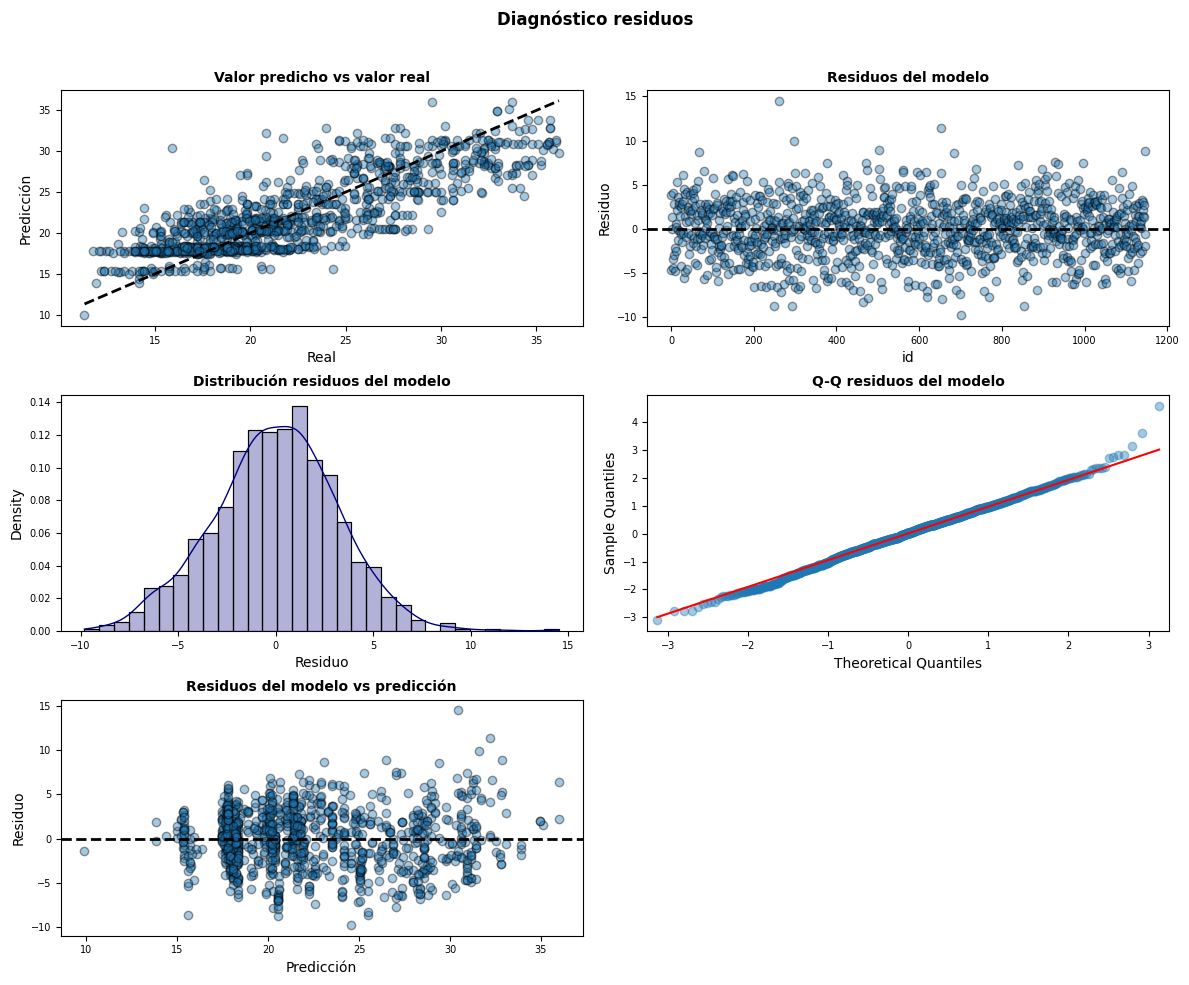

In [270]:
# Gráficos para el pronóstico de residuos

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 10))

axes[0, 0].scatter(y_train, prediccion_train, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()],
                '--', color = 'black', lw=2)
axes[0, 0].set_title('Valor predicho vs valor real', fontsize = 10, fontweight = "bold")
axes[0, 0].set_xlabel('Real')
axes[0, 0].set_ylabel('Predicción')
axes[0, 0].tick_params(labelsize = 7)

axes[0, 1].scatter(list(range(len(y_train))), residuos_train,
                   edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 1].axhline(y = 0, linestyle = '--', color = 'black', lw=2)
axes[0, 1].set_title('Residuos del modelo', fontsize = 10, fontweight = "bold")
axes[0, 1].set_xlabel('id')
axes[0, 1].set_ylabel('Residuo')
axes[0, 1].tick_params(labelsize = 7)

sns.histplot(
    data    = residuos_train,
    stat    = "density",
    kde     = True,
    line_kws= {'linewidth': 1},
    color   =  "navy",#"firebrick",
    alpha   = 0.3,
    ax      = axes[1, 0]
)

axes[1, 0].set_title('Distribución residuos del modelo', fontsize = 10,
                     fontweight = "bold")
axes[1, 0].set_xlabel("Residuo")
axes[1, 0].tick_params(labelsize = 7)


sm.qqplot(
    residuos_train,
    fit   = True,
    line  = 'q',
    ax    = axes[1, 1],
    color = 'navy', #'firebrick',
    alpha = 0.4,
    lw    = 2
)
axes[1, 1].set_title('Q-Q residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 1].tick_params(labelsize = 7)

axes[2, 0].scatter(prediccion_train, residuos_train,
                   edgecolors=(0, 0, 0), alpha = 0.4)
axes[2, 0].axhline(y = 0, linestyle = '--', color = 'black', lw=2)
axes[2, 0].set_title('Residuos del modelo vs predicción', fontsize = 10, fontweight = "bold")
axes[2, 0].set_xlabel('Predicción')
axes[2, 0].set_ylabel('Residuo')
axes[2, 0].tick_params(labelsize = 7)

# Se eliminan los axes vacíos
fig.delaxes(axes[2,1])

fig.tight_layout()
plt.subplots_adjust(top=0.9)
fig.suptitle('Diagnóstico residuos', fontsize = 12, fontweight = "bold");

### Test

In [271]:
#Se extraen solo las columnas que finalmente quedaron en X_train (excluyendo constante)
X_test = X_test[modelo_X_train.columns[1:len(modelo_X_train)]]

#Adicionamos la constante
X_test = sm.add_constant(X_test)

In [272]:
# Error de prueba (test) del modelo


predicciones = modelLRegresion.predict(X_test)

mse = mean_squared_error (y_true  = y_test, y_pred  = predicciones)
rmse = np.sqrt (mse)
MAE = mean_absolute_error (y_true  = y_test, y_pred  = predicciones)
MedAE = median_absolute_error (y_true  = y_test, y_pred  = predicciones)
r2 = r2_score (y_true  = y_test, y_pred  = predicciones)

print(f"El error MSE   de test es: {mse}")
print(f"El error RMSE  de test es: {rmse}")
print(f"El error MAE   de test es: {MAE}")
print(f"El error MedAE de test es: {MedAE}")
print(f"El error R2    de test es: {r2}")

El error MSE   de test es: 10.480199184464128
El error RMSE  de test es: 3.2373135752447784
El error MAE   de test es: 2.486721408551414
El error MedAE de test es: 2.040816423191144
El error R2    de test es: 0.6446269030926303


In [273]:
X_test

,const,PriceRange,Fuel Tank Capacity,Fuel Type_Otro,Fuel Type_Petrol,Transmission_Manual,Owner_Fourth,Owner_Second,Owner_Third,Drivetrain_FWD,Drivetrain_RWD
630,1.0000,0.0000,0.2768,0,0,0,0,0,0,1,0
454,1.0000,0.0000,0.0598,1,0,1,0,0,0,1,0
148,1.0000,0.0000,0.1350,0,0,1,0,0,0,1,0
110,1.0000,0.2500,0.3461,0,0,1,0,1,0,0,1
1054,1.0000,0.0000,0.0598,0,1,1,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
99,1.0000,0.0000,0.0598,1,0,1,0,1,0,1,0
854,1.0000,0.5000,0.2135,0,1,0,0,0,0,1,0
202,1.0000,0.5000,0.3461,0,0,0,0,1,0,1,0
648,1.0000,0.0000,0.1350,0,1,0,0,0,0,1,0


In [274]:
modelLRegresion.predict(X_test)

,0
630,24.4476
454,17.7397
148,20.0802
110,21.0447
1054,15.3508
...,...
99,15.2938
854,26.1001
202,26.2703
648,21.7784


In [275]:
# Concatenar X_test y y_test
df_prep = pd.DataFrame(np.c_[X_test, y_test], columns= X_test.columns.tolist()+['PriceReal'])
df_prep

,const,PriceRange,Fuel Tank Capacity,Fuel Type_Otro,Fuel Type_Petrol,Transmission_Manual,Owner_Fourth,Owner_Second,Owner_Third,Drivetrain_FWD,Drivetrain_RWD,PriceReal
0,1.0000,0.0000,0.2768,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,25.7631
1,1.0000,0.0000,0.0598,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,14.6123
2,1.0000,0.0000,0.1350,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,18.6434
3,1.0000,0.2500,0.3461,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000,22.5062
4,1.0000,0.0000,0.0598,0.0000,1.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,11.5978
...,...,...,...,...,...,...,...,...,...,...,...,...
283,1.0000,0.0000,0.0598,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,12.0277
284,1.0000,0.5000,0.2135,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,27.6417
285,1.0000,0.5000,0.3461,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,27.2703
286,1.0000,0.0000,0.1350,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,20.9841


In [276]:
# Predecir los valores para df_prep utilizando el modelLRegresion y Elevar al cubo usando np.power()
resultadoPredict =np.power(modelLRegresion.predict(df_prep.drop(columns ='PriceReal')), 3)
resultadoPredict

,0
0,14612.0220
1,5582.6207
2,8096.5994
3,9320.2384
4,3617.3846
...,...
283,3577.1978
284,17779.7138
285,18129.8668
286,10329.3988


In [277]:
# Convertir el array numpy resultadoPredic en un DataFrame de pandas
resultadoPredict_df = pd.DataFrame(resultadoPredict, columns=['PricePredict'])
resultadoPredict_df

,PricePredict
0,14612.0220
1,5582.6207
2,8096.5994
3,9320.2384
4,3617.3846
...,...
283,3577.1978
284,17779.7138
285,18129.8668
286,10329.3988


In [278]:
# Concatenar x_i con el DataFrame de las predicciones
concatenated_df = pd.concat([df_prep.reset_index(drop=True), resultadoPredict_df], axis=1)

# el precio real se eleva al cubo
concatenated_df['PriceReal'] = np.power(concatenated_df['PriceReal'],3)

In [279]:
# Se calcula el valor absoluto de la diferencia entre el precio real y el precio calculado
concatenated_df['dif'] = (concatenated_df['PriceReal'] - concatenated_df['PricePredict']).abs()

In [280]:
# Las diferencias ordenadas
concatenated_df[['PriceReal', 'PricePredict', 'dif']].sort_values(by='dif', ascending=True)

,PriceReal,PricePredict,dif
94,6000.0000,6002.2831,2.2831
80,6000.0000,6002.2831,2.2831
122,10320.0000,10309.0864,10.9136
145,8520.0000,8487.4463,32.5537
14,9900.0000,9859.3067,40.6933
...,...,...,...
68,38340.0000,16511.4052,21828.5948
110,8100.0000,31051.3563,22951.3563
228,42000.0000,18380.6187,23619.3813
56,5940.0000,31051.3563,25111.3563


In [281]:
# Principales descripciones de las diferencias
print(concatenated_df['dif'].describe())

count     288.0000
mean     3789.6810
std      4168.1179
min         2.2831
25%      1038.0819
50%      2596.0550
75%      4965.4103
max     26685.8780
Name: dif, dtype: float64


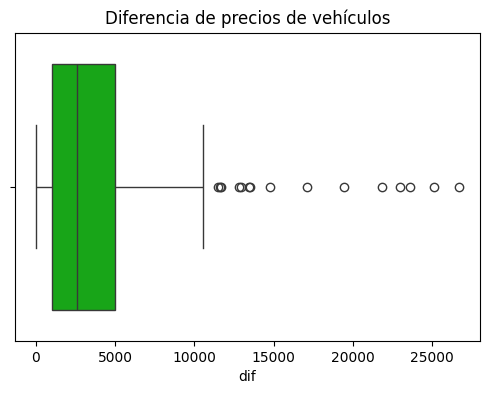

In [282]:
#Caja de bigotes de las diferencias de los precios

plt.figure(figsize=(6,4))

plt.title('Diferencia de precios de vehículos')
sns.boxplot(x=concatenated_df['dif'], palette='nipy_spectral')

plt.show()

#### Referencias

- *Regresion Lineal en Python:*
    - https://www.cienciadedatos.net/documentos/py10-regresion-lineal-python.html
  
  
- *Machine learning con Python y Scikit-learn:*
    - https://www.cienciadedatos.net/documentos/py06_machine_learning_python_scikitlearn.html
    

- *scikit-learn:*    
    - https://scikit-learn.org/stable/
    - https://scikit-learn.org/stable/user_guide.html
  
  
- *Recursive Feature Elimination (RFE)*:
    - https://www.kaggle.com/goyalshalini93/car-price-prediction-linear-regression-rfe
    - https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html


- *Gráficas con  seaborn:*
    - https://ichi.pro/es/como-utilizar-python-seaborn-para-analisis-de-datos-exploratorios-28897898172180


- *Multicolinealidad:*
    - https://www.analyticslane.com/2020/04/22/solucionar-la-multicolinealidad-con-vif/


- *Analítica de grandes datos:*
    - https://jdvelasq.github.io/courses/analitica-de-grandes-datos/index.html